# 02. Exploratory Data Analysis (EDA)
we explore the cleaned dataset through visualization to understand student burnout risk levels and how academic workload, sleep, and emotional exhaustion relate to risk.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Load cleaned dataset
data_path = Path('../data/processed/cognivault_cleaned_dataset.csv')
df = pd.read_csv(data_path)
print(f"Loaded {df.shape[0]} student records with {df.shape[1]} columns.")
df.head(3)


Loaded 1900 student records with 16 columns.


,institution,degree,year,branch,living_arrangement,study_hours_outside_classes_per_day,academic_tasks_per_week,academic_workload,time_pressure,avg_sleep_hours,wakes_up_tired,physical_activity_days_per_week,difficulty_concentrating,academic_emotional_exhaustion,burnout_risk_score,burnout_risk_level
0,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,8,4,4,5.2,5,2,3,4,57.1,High
1,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,9,4,3,6.0,4,1,3,3,59.7,High
2,IIIT Pune,B.Tech,1,Cyber Security,Hostel,3.5,7,3,3,6.7,2,2,2,1,28.4,Low


### 1. Burnout Risk Level Distribution
Let's see how students are distributed across the four burnout risk levels: Low, Moderate, High, and Critical.


C:\Users\gicsc\AppData\Local\Temp\ipykernel_18940\1337102583.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='burnout_risk_level', order=risk_order, palette=palette)


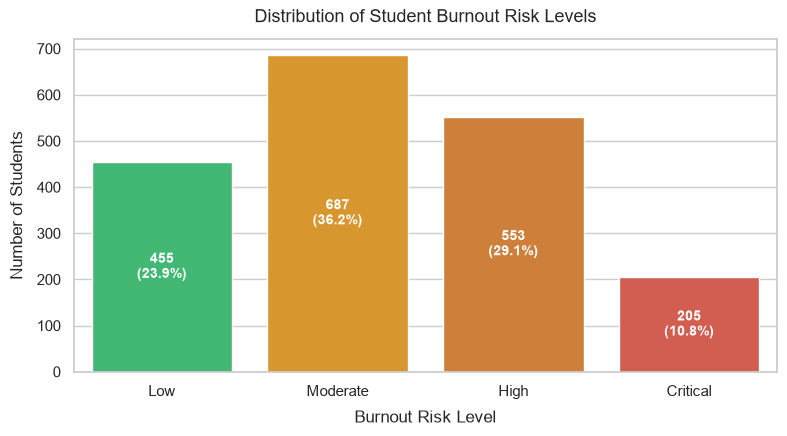

In [ ]:
risk_order = ['Low', 'Moderate', 'High', 'Critical']
palette = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=df, x='burnout_risk_level', order=risk_order, palette=palette)
plt.title('Distribution of Student Burnout Risk Levels', fontsize=13, pad=12)
plt.xlabel('Burnout Risk Level', labelpad=8)
plt.ylabel('Number of Students', labelpad=8)

# Add count and percentage labels above bars
total = len(df)
for p in ax.patches:
    height = int(p.get_height())
    pct = (height / total) * 100
    ax.annotate(f'{height}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


**Observation:**
- **Moderate Risk** is the largest group (687 students, 36.2%), followed by **High Risk** (553 students, 29.1%) and **Low Risk** (455 students, 24.0%).
- **Critical Risk** is the smallest group (205 students, 10.8%).
- Because Critical is a minority class, we should evaluate our models using Macro F1-score and use balanced class weighting so the model pays equal attention to all levels.


### 2. Key Lifestyle and Academic Feature Distributions
We look at three important continuous variables: average sleep hours, daily study hours outside class, and academic tasks per week.


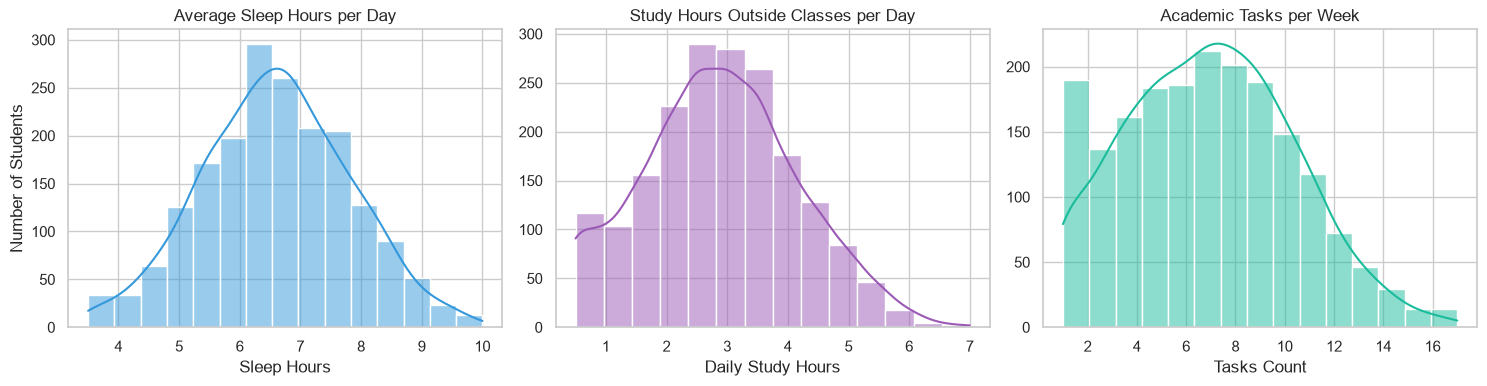

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Sleep hours distribution
sns.histplot(df['avg_sleep_hours'], kde=True, color='#3498db', bins=15, ax=axes[0])
axes[0].set_title('Average Sleep Hours per Day')
axes[0].set_xlabel('Sleep Hours')
axes[0].set_ylabel('Number of Students')

# Study hours distribution
sns.histplot(df['study_hours_outside_classes_per_day'], kde=True, color='#9b59b6', bins=14, ax=axes[1])
axes[1].set_title('Study Hours Outside Classes per Day')
axes[1].set_xlabel('Daily Study Hours')
axes[1].set_ylabel('')

# Academic tasks per week
sns.histplot(df['academic_tasks_per_week'], kde=True, color='#1abc9c', bins=15, ax=axes[2])
axes[2].set_title('Academic Tasks per Week')
axes[2].set_xlabel('Tasks Count')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


**Observation:**
- Most students report sleeping between **5.5 and 7.5 hours per night**, with an average around 6.6 hours.
- Daily study time outside class centers between **2.0 and 5.0 hours**.
- The number of weekly academic tasks ranges from 1 to 17, with most students handling 6 to 12 tasks weekly.


### 3. Comparing Habits Across Burnout Risk Levels
compare sleep hours, emotional exhaustion, and physical activity across the four risk categories.


C:\Users\gicsc\AppData\Local\Temp\ipykernel_18940\3690538508.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='burnout_risk_level', y='avg_sleep_hours', order=risk_order, palette=palette, ax=axes[0])
C:\Users\gicsc\AppData\Local\Temp\ipykernel_18940\3690538508.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='burnout_risk_level', y='academic_emotional_exhaustion', order=risk_order, palette=palette, ax=axes[1])
C:\Users\gicsc\AppData\Local\Temp\ipykernel_18940\3690538508.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='burnout_risk_level', y='physical_activity_days_per_week', order=risk

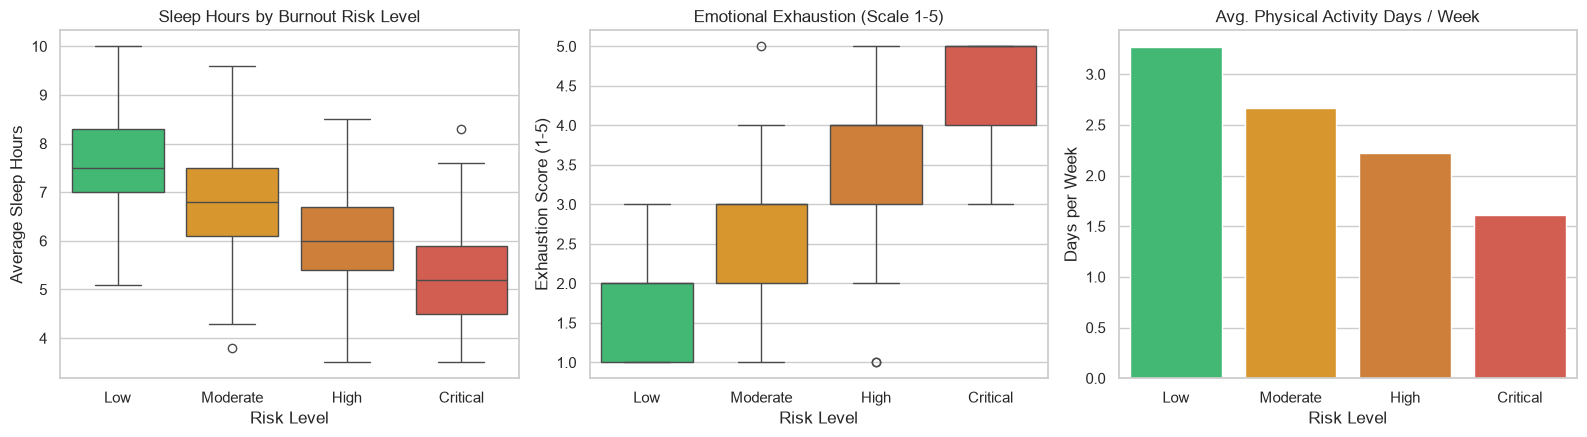

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Sleep hours across risk levels
sns.boxplot(data=df, x='burnout_risk_level', y='avg_sleep_hours', order=risk_order, palette=palette, ax=axes[0])
axes[0].set_title('Sleep Hours by Burnout Risk Level')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Average Sleep Hours')

# Academic emotional exhaustion across risk levels
sns.boxplot(data=df, x='burnout_risk_level', y='academic_emotional_exhaustion', order=risk_order, palette=palette, ax=axes[1])
axes[1].set_title('Emotional Exhaustion (Scale 1-5)')
axes[1].set_xlabel('Risk Level')
axes[1].set_ylabel('Exhaustion Score (1-5)')

# Physical activity days per week
sns.barplot(data=df, x='burnout_risk_level', y='physical_activity_days_per_week', order=risk_order, palette=palette, ci=None, ax=axes[2])
axes[2].set_title('Avg. Physical Activity Days / Week')
axes[2].set_xlabel('Risk Level')
axes[2].set_ylabel('Days per Week')

plt.tight_layout()
plt.show()


**Observation:**
- **Sleep:** Students in the Low risk category average over 7.5 hours of sleep, while High and Critical risk students average 4.5 to 5.5 hours.
- **Emotional Exhaustion:** Low risk students report very low emotional exhaustion (median 1-2), while Critical risk students consistently report high exhaustion (median 4-5).
- **Physical Activity:** Students in the Low risk group average ~3.4 days of physical activity per week, compared to only ~1.5 days for students in the Critical group.


### 4. Correlation Heatmap
We compute Pearson correlations between the numeric survey features and the burnout risk score.


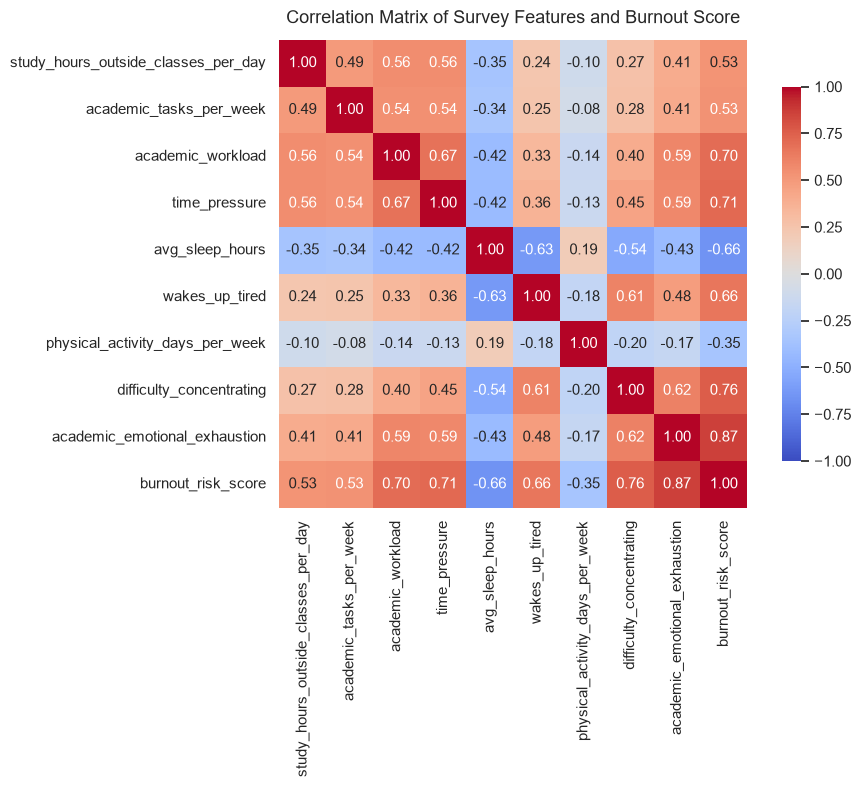

In [5]:
numeric_features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
    'burnout_risk_score'
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Survey Features and Burnout Score', fontsize=13, pad=12)
plt.tight_layout()
plt.show()


**Observation:**
- **Strongest Positive Correlations with Burnout Score:**
  - `academic_emotional_exhaustion` ($r = 0.87$)
  - `difficulty_concentrating` ($r = 0.76$)
  - `time_pressure` ($r = 0.71$)
  - `academic_workload` ($r = 0.70$)
- **Strongest Negative Correlation:**
  - `avg_sleep_hours` ($r = -0.66$)


### 5. Exploring Potential Outliers in the Nine Input Features

A boxplot shows the median and the middle half of the data (from the first quartile, Q1, to the third quartile, Q3). The interquartile range (IQR) is `Q3 - Q1`. The common 1.5 × IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` as potential outliers. A flagged value is unusual, not automatically an error, so it should be investigated before anyone considers removing it.

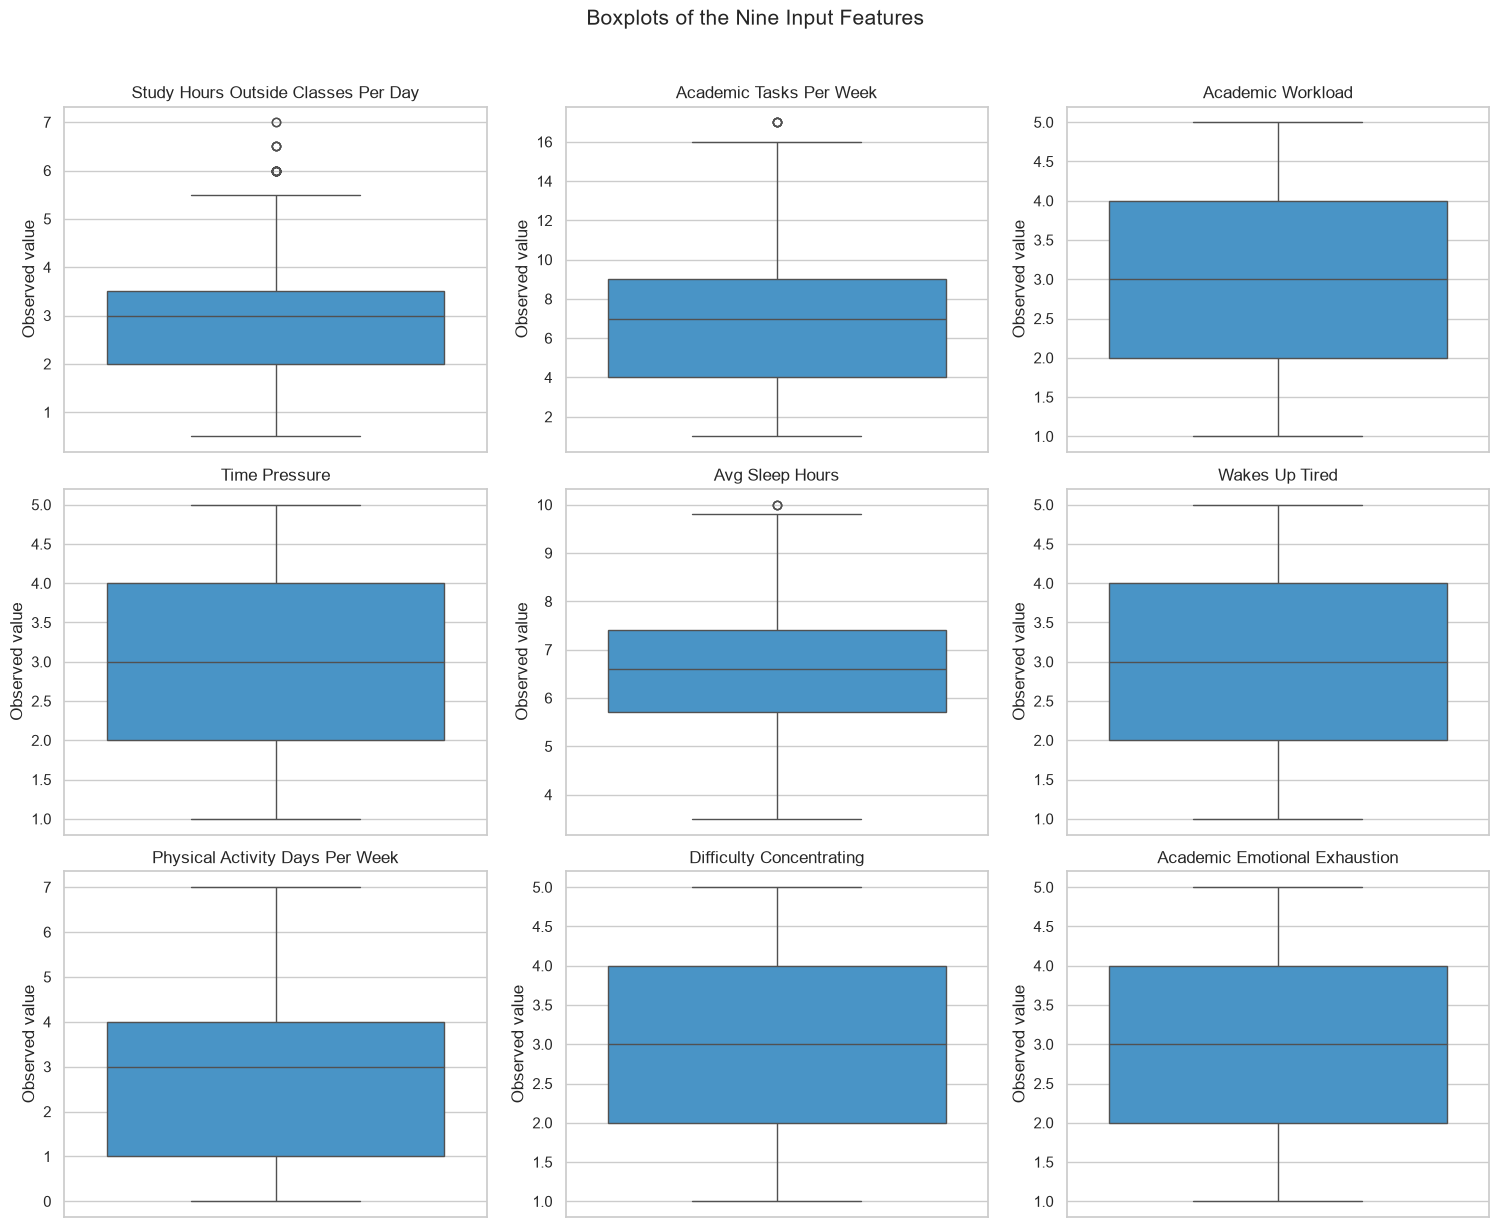

,Feature,Lower fence,Upper fence,Potential outliers
0,study_hours_outside_classes_per_day,-0.25,5.75,24
1,academic_tasks_per_week,-3.50,16.50,5
2,academic_workload,-1.00,7.00,0
3,time_pressure,-1.00,7.00,0
4,avg_sleep_hours,3.15,9.95,3
5,wakes_up_tired,-1.00,7.00,0
6,physical_activity_days_per_week,-3.50,8.50,0
7,difficulty_concentrating,-1.00,7.00,0
8,academic_emotional_exhaustion,-1.00,7.00,0


In [ ]:
# These are the nine input features; neither burnout target is included.
feature_columns = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
outlier_summary = []

for feature, ax in zip(feature_columns, axes.flat):
    sns.boxplot(y=df[feature], color='#3498db', ax=ax)
    ax.set_title(feature.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_ylabel('Observed value')

    first_quartile = df[feature].quantile(0.25)
    third_quartile = df[feature].quantile(0.75)
    interquartile_range = third_quartile - first_quartile
    lower_fence = first_quartile - 1.5 * interquartile_range
    upper_fence = third_quartile + 1.5 * interquartile_range
    potential_outliers = (df[feature] < lower_fence) | (df[feature] > upper_fence)
    outlier_summary.append({
        'Feature': feature,
        'Lower fence': lower_fence,
        'Upper fence': upper_fence,
        'Potential outliers': int(potential_outliers.sum()),
    })

fig.suptitle('Boxplots of the Nine Input Features', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame(outlier_summary).round(2)

**What the current data shows:** The 1.5 × IQR rule flags 24 study-hour values above 5.75 hours per day (18 values of 6.0, 4 of 6.5, and 2 of 7.0), 5 weekly task counts of 17, and 3 sleep values of 10.0 hours. It flags no values in the other six features. These are potential outliers under this statistical rule only; the code keeps every observation unchanged.

### 6. Comparing Risk Classes with Scatter Plots

Each dot is one record. Its position represents two feature values, while its colour shows the existing `burnout_risk_level`. Looking for clusters and overlap helps us understand how these pairs relate to the classes; it does not by itself prove that classes can be cleanly separated.

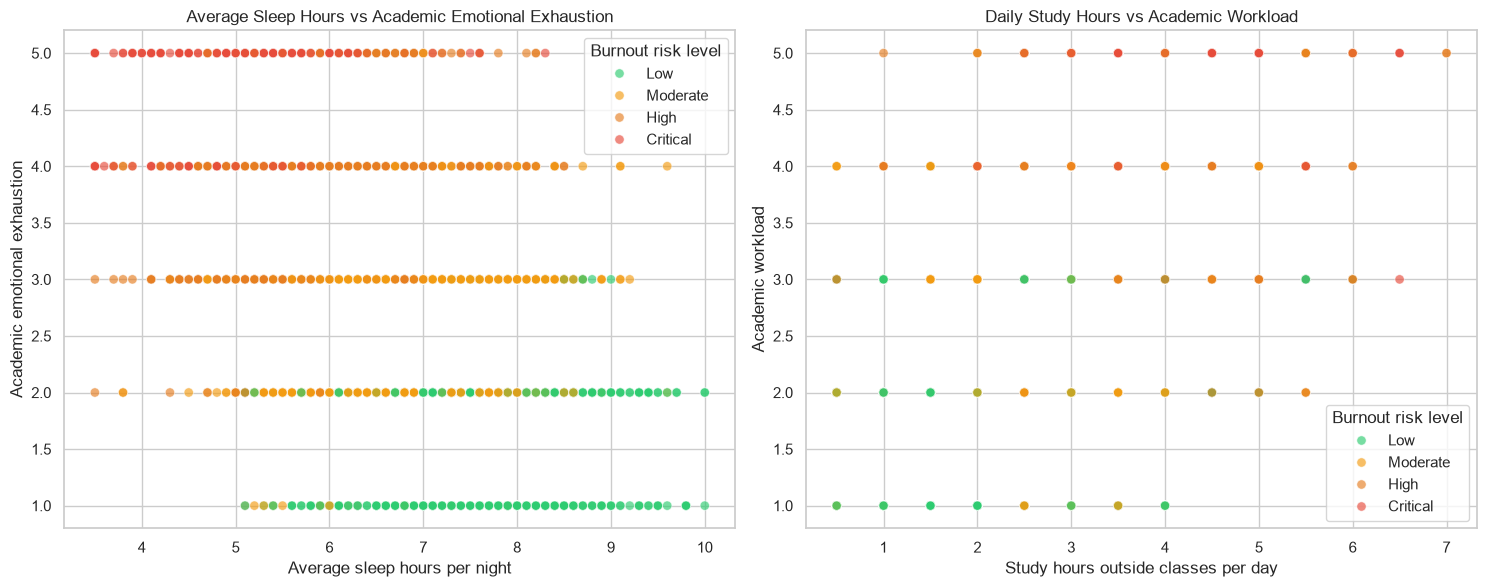

In [ ]:
class_colors = dict(zip(risk_order, palette))
scatter_pairs = [
    (
        'avg_sleep_hours',
        'academic_emotional_exhaustion',
        'Average Sleep Hours vs Academic Emotional Exhaustion',
        'Average sleep hours per night',
        'Academic emotional exhaustion',
    ),
    (
        'study_hours_outside_classes_per_day',
        'academic_workload',
        'Daily Study Hours vs Academic Workload',
        'Study hours outside classes per day',
        'Academic workload',
    ),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (x_feature, y_feature, title, x_label, y_label) in zip(axes, scatter_pairs):
    sns.scatterplot(
        data=df,
        x=x_feature,
        y=y_feature,
        hue='burnout_risk_level',
        hue_order=risk_order,
        palette=class_colors,
        alpha=0.65,
        s=45,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.legend(title='Burnout risk level')

plt.tight_layout()
plt.show()

**What the plots suggest:** Low-risk records tend to appear at higher sleep and lower exhaustion, while High and Critical records more often appear at lower sleep and higher exhaustion. In the study-hours and workload plot, High and Critical records tend to have higher workload ratings, while Low records more often have lower ratings. The colours still overlap in both plots, so these pairs show trends rather than perfectly separated classes.

### 7. Decision Regions from the Existing Logistic Regression Model

This plot uses the saved model only to make predictions; it does not train or save a model. It shows a two-feature slice of the existing nine-feature model: sleep hours and emotional exhaustion vary across the plot, while the other seven features stay fixed at their cleaned-dataset medians. The regions can change if those seven fixed values change.

d:\Miniconda3\envs\ml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Miniconda3\envs\ml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Miniconda3\envs\ml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using version 1.9.0. This might lead to breaking code or in

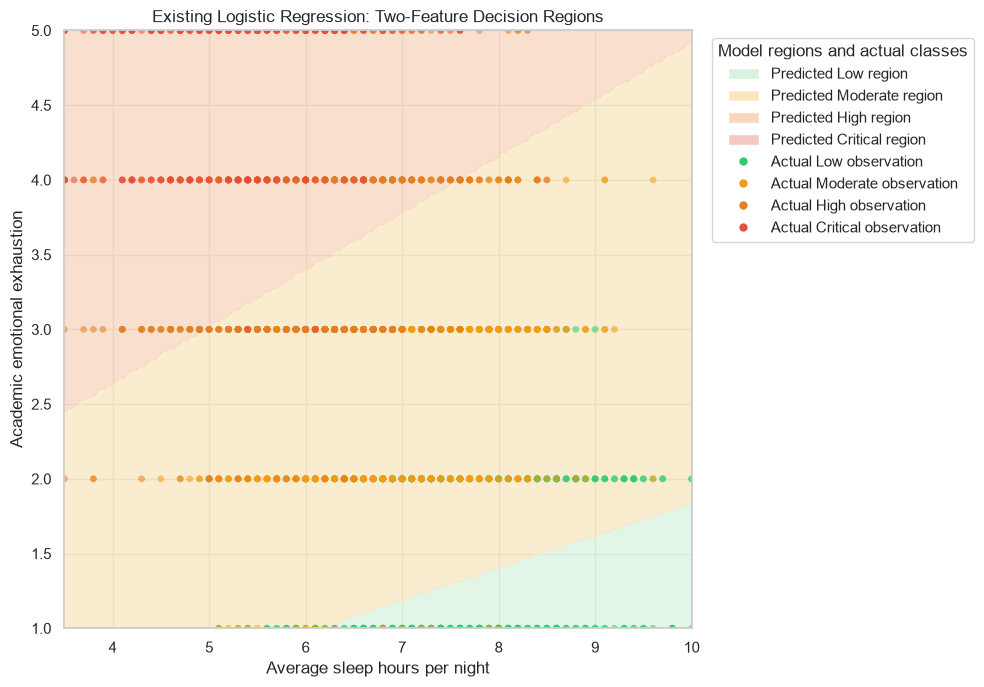

In [ ]:
import joblib
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Locate the project folder whether Jupyter started at the repository root or in notebooks/.
possible_project_roots = [Path.cwd(), Path.cwd().parent]
project_root = next(
    (
        path
        for path in possible_project_roots
        if (path / 'data' / 'processed' / 'cognivault_cleaned_dataset.csv').exists()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate the Cognivault project and cleaned dataset.')

model_path = project_root / 'models' / 'logistic_regression_model.joblib'
if not model_path.exists():
    raise FileNotFoundError(f'Saved logistic regression model not found: {model_path}')

# Load the existing pipeline for prediction only. Do not fit or save it here.
saved_model = joblib.load(model_path)
if list(saved_model.feature_names_in_) != feature_columns:
    raise ValueError('Saved model feature names/order do not match the nine input features.')

x_feature = 'avg_sleep_hours'
y_feature = 'academic_emotional_exhaustion'
grid_x_values = np.linspace(df[x_feature].min(), df[x_feature].max(), 160)
grid_y_values = np.linspace(df[y_feature].min(), df[y_feature].max(), 160)
mesh_x, mesh_y = np.meshgrid(grid_x_values, grid_y_values)

# Start every grid row at the dataset medians, then vary only the two plotted features.
median_values = df[feature_columns].median()
grid_inputs = pd.DataFrame(
    np.tile(median_values.to_numpy(), (mesh_x.size, 1)),
    columns=feature_columns,
)
grid_inputs[x_feature] = mesh_x.ravel()
grid_inputs[y_feature] = mesh_y.ravel()
grid_inputs = grid_inputs.loc[:, feature_columns]

predicted_classes = saved_model.predict(grid_inputs)
class_to_number = {risk_level: number for number, risk_level in enumerate(risk_order)}
predicted_numbers = np.array([class_to_number[label] for label in predicted_classes])
predicted_regions = predicted_numbers.reshape(mesh_x.shape)

background_colors = ['#d9f2df', '#f9e7bf', '#f8d5bd', '#f4c7c3']
observation_colors = dict(zip(risk_order, palette))
fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(
    mesh_x,
    mesh_y,
    predicted_regions,
    levels=np.arange(len(risk_order) + 1) - 0.5,
    colors=background_colors,
    alpha=0.75,
)

for risk_level in risk_order:
    class_mask = df['burnout_risk_level'] == risk_level
    ax.scatter(
        df.loc[class_mask, x_feature],
        df.loc[class_mask, y_feature],
        color=observation_colors[risk_level],
        label=f'Actual {risk_level}',
        alpha=0.55,
        s=24,
        edgecolors='none',
    )

legend_handles = [
    Patch(facecolor=background_colors[index], label=f'Predicted {risk_level} region')
    for index, risk_level in enumerate(risk_order)
]
legend_handles.extend(
    Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=observation_colors[risk_level],
        markersize=7,
        label=f'Actual {risk_level} observation',
    )
    for risk_level in risk_order
)
ax.legend(handles=legend_handles, title='Model regions and actual classes', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_title('Existing Logistic Regression: Two-Feature Decision Regions')
ax.set_xlabel('Average sleep hours per night')
ax.set_ylabel('Academic emotional exhaustion')
plt.tight_layout()
plt.show()